### Week 1: Explore a Dataset with Pandas

This week, I explored the Titanic dataset using Pandas to understand the data, identify missing values, and analyze survival patterns.

- Loaded and inspected the dataset using `head()`, `info()`, and `describe()`.
- Identified missing values using `isnull().sum()`.
- Analyzed survival rates by passenger class and gender using `groupby()`.
- Created visualizations using Matplotlib and Seaborn.
- Observed survival patterns and explored the passenger age distribution.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Titanic dataset
df = sns.load_dataset('titanic')

# Display first five rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# First 5 rows
df.head()

# Dataset shape (rows, columns)
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [4]:
print(missing_values[missing_values > 0])

age            177
embarked         2
deck           688
embark_town      2
dtype: int64


In [5]:
# Survival rate by passenger class
class_survival = df.groupby('pclass')['survived'].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

Survival Rate by Passenger Class:
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64


In [6]:
# Survival rate by gender
gender_survival = df.groupby('sex')['survived'].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival.round(2))

Survival Rate by Gender:
sex
female    74.20
male      18.89
Name: survived, dtype: float64


In [7]:
class_gender = df.groupby(['pclass', 'sex'])['survived'].mean() * 100

print(class_gender.round(2))

pclass  sex   
1       female    96.81
        male      36.89
2       female    92.11
        male      15.74
3       female    50.00
        male      13.54
Name: survived, dtype: float64


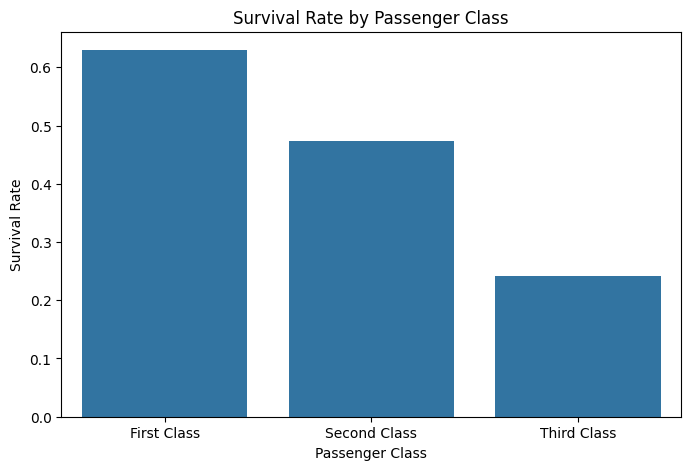

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x='pclass',
    y='survived',
    data=df,
    errorbar=None
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.xticks([0, 1, 2], ['First Class', 'Second Class', 'Third Class'])

plt.savefig('survival_by_class.png', dpi=300, bbox_inches='tight')
plt.show()

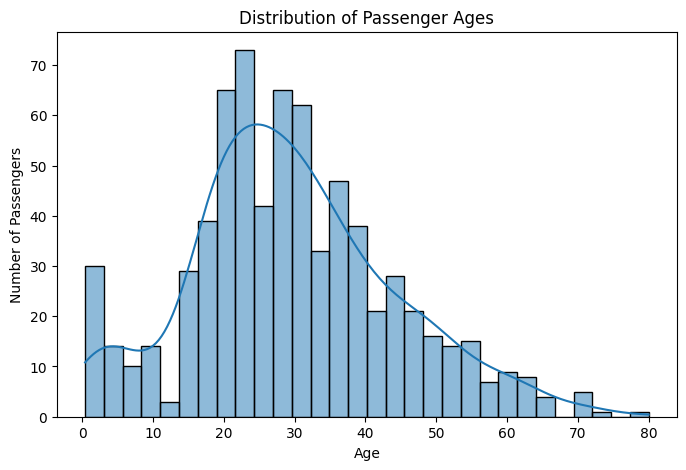

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df['age'].dropna(), bins=30, kde=True)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.savefig('age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
best_class = class_survival.idxmax()
best_gender = gender_survival.idxmax()

print(f"Total passengers: {len(df)}")

print(
    f"Passenger class with the highest survival rate: "
    f"{best_class} ({class_survival.max():.2f}%)"
)

print(
    f"Gender with the highest survival rate: "
    f"{best_gender} ({gender_survival.max():.2f}%)"
)

Total passengers: 891
Passenger class with the highest survival rate: 1 (62.96%)
Gender with the highest survival rate: female (74.20%)


The Titanic dataset contains 891 passenger records. The analysis shows that first-class passengers had the highest survival rate of 62.96%. Female passengers had a higher survival rate of 74.20% compared to male passengers. This analysis highlights the relationship between passenger class, gender and survival rates.

Results:
- Total passengers: 891
- Highest survival rate by class: First Class (62.96%)
- Highest survival rate by gender: Female (74.20%)

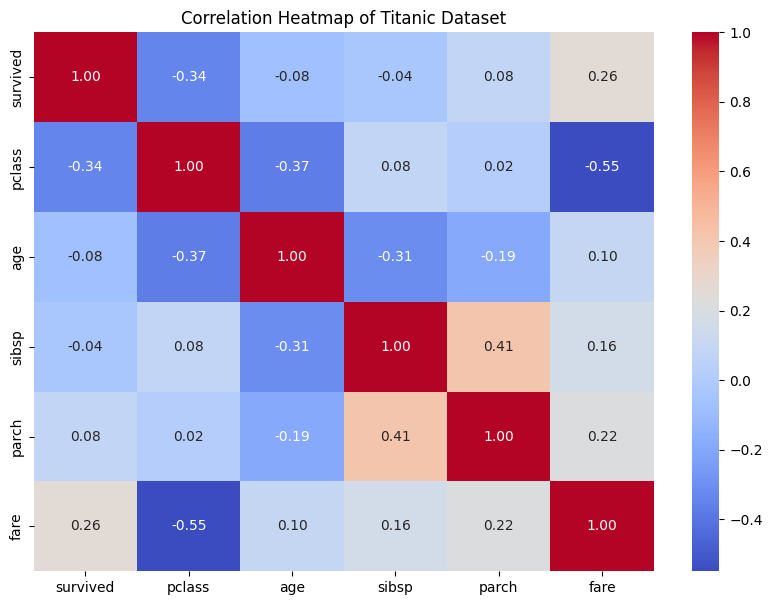

In [11]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Titanic Dataset')
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Week 2: Data Cleaning and Feature Engineering

In this week, I will clean the Titanic dataset by handling missing values, creating new features, converting categorical variables into numeric values, and detecting outliers. This will help prepare the dataset for further analysis and machine learning.


In [12]:
# Check missing values in the dataset
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


1. Handling Missing Values

    Age: The missing age values will be replaced with the median age because the median is less affected by outliers.
    Embarked: The two missing values will be replaced with the most frequent value (mode).
    Deck: This column will be removed because a large proportion of its values are missing.
    Embark_town: This column will be removed because it contains redundant information already available in the embarked column.

These strategies help maintain useful information while preparing the dataset for further analysis.


In [13]:
def clean_data(df):
    data = df.copy()

    # Fill missing Age values with median
    data['age'] = data['age'].fillna(data['age'].median())

    # Fill missing Embarked values with mode
    data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0])

    # Drop columns with too many missing or redundant values
    data = data.drop(columns=['deck', 'embark_town'])

    return data

# Apply the cleaning function
cleaned_df = clean_data(df)

# Check missing values after cleaning
cleaned_df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


### 2. Feature Engineering

Feature engineering involves creating new features from existing data to make it more useful for analysis and machine learning.

- **Family Size:** Calculated by adding the number of siblings/spouses (`sibsp`), parents/children (`parch`), and the passenger themselves.
- **Is Alone:** A new column that identifies whether a passenger was travelling alone. If the family size is 1, the passenger is considered alone; otherwise, they are travelling with family.

In [14]:
# Create Family Size feature
cleaned_df['family_size'] = cleaned_df['sibsp'] + cleaned_df['parch'] + 1

# Create Is Alone feature
cleaned_df['is_alone'] = cleaned_df['family_size'] == 1

# Display the new features
cleaned_df[['sibsp', 'parch', 'family_size', 'is_alone']].head(10)

,sibsp,parch,family_size,is_alone
0,1,0,2,False
1,1,0,2,False
2,0,0,1,True
3,1,0,2,False
4,0,0,1,True
5,0,0,1,True
6,0,0,1,True
7,3,1,5,False
8,0,2,3,False
9,1,0,2,False


3. Categorical Encoding

Categorical encoding converts categorical data into numerical values so that it can be used in machine learning algorithms.

I will use pandas.get_dummies() to encode the sex and embarked columns. This creates separate numeric columns for the different categories, making the data suitable for further analysis and modeling.

In [15]:
# Encode categorical columns
cleaned_df = pd.get_dummies(
    cleaned_df,
    columns=['sex', 'embarked'],
    dtype=int
)

# Display the encoded columns
cleaned_df.head()

,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,alive,alone,family_size,is_alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,Third,man,True,no,False,2,False,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,First,woman,False,yes,False,2,False,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,Third,woman,False,yes,True,1,True,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,First,woman,False,yes,False,2,False,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,Third,man,True,no,True,1,True,0,1,0,0,1


4. Outlier Detection

A boxplot is used to identify outliers in the fare column. Outliers are values that are unusually high or low compared to the rest of the data.

I will use a boxplot to visualize the fare distribution. Since the higher ticket fares may represent genuine passengers who purchased expensive tickets, I will keep these outliers rather than remove or cap them. They may provide useful information for analysis.

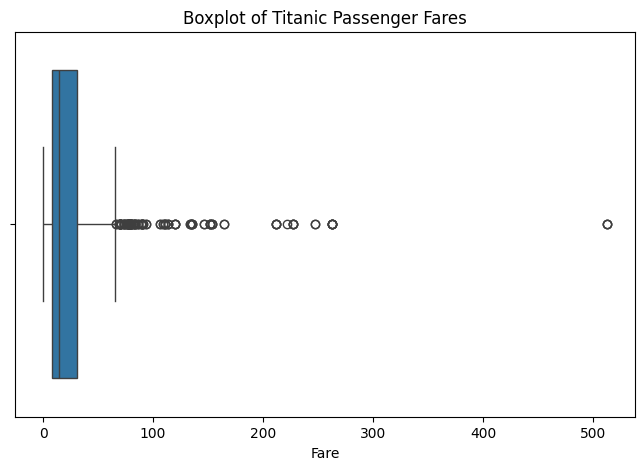

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot to detect Fare outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=cleaned_df['fare'])

plt.title('Boxplot of Titanic Passenger Fares')
plt.xlabel('Fare')

plt.show()

5. Survival Analysis on Cleaned Data

After cleaning the dataset and creating new features, I will re-run the groupby analysis to examine survival rates across passenger classes and gender. This helps verify that the cleaned dataset still provides meaningful insights.

In [17]:
# Survival rate by passenger class
cleaned_df.groupby('pclass')['survived'].mean() * 100

,survived
pclass,
1,62.962963
2,47.282609
3,24.236253


In [18]:
# Survival rate by gender
female_survival = cleaned_df.groupby('sex_female')['survived'].mean() * 100

female_survival

,survived
sex_female,
0,18.890815
1,74.203822


In [19]:
# Display survival rate by gender with labels
print("Male Survival Rate:", cleaned_df[cleaned_df['sex_male'] == 1]['survived'].mean() * 100)
print("Female Survival Rate:", cleaned_df[cleaned_df['sex_female'] == 1]['survived'].mean() * 100)

Male Survival Rate: 18.890814558058924
Female Survival Rate: 74.20382165605095


In [20]:
import os

# Create data folder
os.makedirs('data', exist_ok=True)

# Save cleaned dataset
cleaned_df.to_csv('data/titanic_clean.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [21]:
# Load the saved dataset
loaded_df = pd.read_csv('data/titanic_clean.csv')

# Check shape and columns
print("Dataset shape:", loaded_df.shape)
print("Columns:", loaded_df.columns.tolist())

loaded_df.head()

Dataset shape: (891, 18)
Columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'alive', 'alone', 'family_size', 'is_alone', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,alive,alone,family_size,is_alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,Third,man,True,no,False,2,False,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,First,woman,False,yes,False,2,False,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,Third,woman,False,yes,True,1,True,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,First,woman,False,yes,False,2,False,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,Third,man,True,no,True,1,True,0,1,0,0,1


In [22]:
from google.colab import files

files.download('data/titanic_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Week 3: Train a Prediction Model with scikit-learn

This week, I used the cleaned Titanic dataset to build and evaluate machine learning models to predict passenger survival using Scikit-learn.

- Loaded the cleaned Titanic dataset and selected relevant input features and the target variable.
- Split the dataset into training and testing sets using `train_test_split()`.
- Trained a Logistic Regression model to predict passenger survival.
- Evaluated the Logistic Regression model using accuracy, precision, recall, and a confusion matrix.
- Trained a Random Forest Classifier using the same training and testing data.
- Evaluated the Random Forest model using classification metrics and a confusion matrix.
- Compared both models to identify the better-performing model.
- Analyzed feature importance to understand which features influenced survival predictions.
- Saved and reloaded the best-performing model using Joblib.

In [23]:
# Select input features
X = cleaned_df[
    [
        'pclass',
        'sex_male',
        'age',
        'sibsp',
        'parch',
        'fare',
        'family_size',
        'is_alone',
        'embarked_C',
        'embarked_Q',
        'embarked_S'
    ]
]

# Select target variable
y = cleaned_df['survived']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 11)
Target Shape: (891,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 11)
Testing Features: (179, 11)
Training Target: (712,)
Testing Target: (179,)


### Model Performance Comparison

In this section, I compared the performance of Logistic Regression and Random Forest Classifier using the same training and testing datasets.

- Compared both models based on accuracy, precision, and recall.
- Evaluated their ability to predict passenger survival.
- Identified the better-performing model based on the evaluation results.
- Used a comparison table to understand the differences in model performance.

This comparison helps determine which machine learning model is more suitable for predicting Titanic passenger survival.

In [25]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
# Predict survival on test data
y_pred_lr = lr_model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual Survival': y_test.values,
    'Predicted Survival': y_pred_lr
})

results.head(10)

,Actual Survival,Predicted Survival
0,1,0
1,0,0
2,0,0
3,1,1
4,1,1
5,1,1
6,1,1
7,0,0
8,1,1
9,1,1


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)

print("Logistic Regression Model Evaluation")
print("------------------------------------")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall:", round(lr_recall * 100, 2), "%")

Logistic Regression Model Evaluation
------------------------------------
Accuracy: 79.89 %
Precision: 77.14 %
Recall: 72.97 %


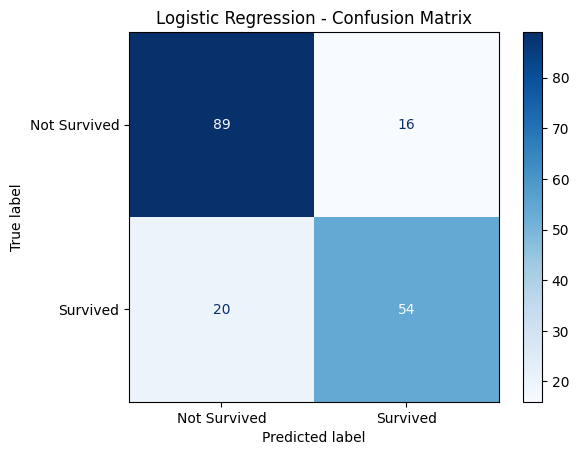

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Not Survived', 'Survived']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [29]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [30]:
# Predict survival on test data
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall:", round(rf_recall * 100, 2), "%")

Random Forest Model Evaluation
--------------------------------
Accuracy: 82.68 %
Precision: 80.28 %
Recall: 77.03 %


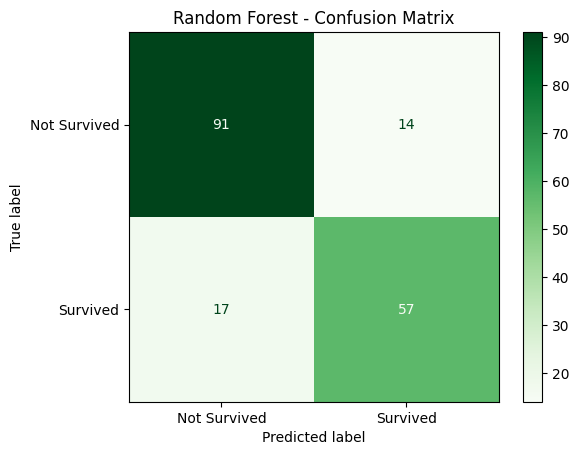

In [31]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Not Survived', 'Survived']
)

disp.plot(cmap='Greens')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [32]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [lr_accuracy, rf_accuracy],
    'Precision': [lr_precision, rf_precision],
    'Recall': [lr_recall, rf_recall]
})

model_comparison[['Accuracy', 'Precision', 'Recall']] = (
    model_comparison[['Accuracy', 'Precision', 'Recall']] * 100
).round(2)

print("Model Performance Comparison")
display(model_comparison)

Model Performance Comparison


,Model,Accuracy,Precision,Recall
0,Logistic Regression,79.89,77.14,72.97
1,Random Forest,82.68,80.28,77.03


### Feature Importance Analysis

In this section, I analyzed the importance of different features using the Random Forest Classifier.

- Extracted feature importance scores from the trained Random Forest model.
- Identified the most influential features in predicting passenger survival.
- Sorted the features based on their importance scores.
- Created a bar chart to visualize the contribution of each feature.

This analysis helps understand which passenger characteristics played a significant role in survival predictions.

In [33]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
5,fare,0.272589
1,sex_male,0.254838
2,age,0.247875
0,pclass,0.073536
6,family_size,0.045616
3,sibsp,0.029140
4,parch,0.023775
10,embarked_S,0.015800
8,embarked_C,0.015719
7,is_alone,0.013389


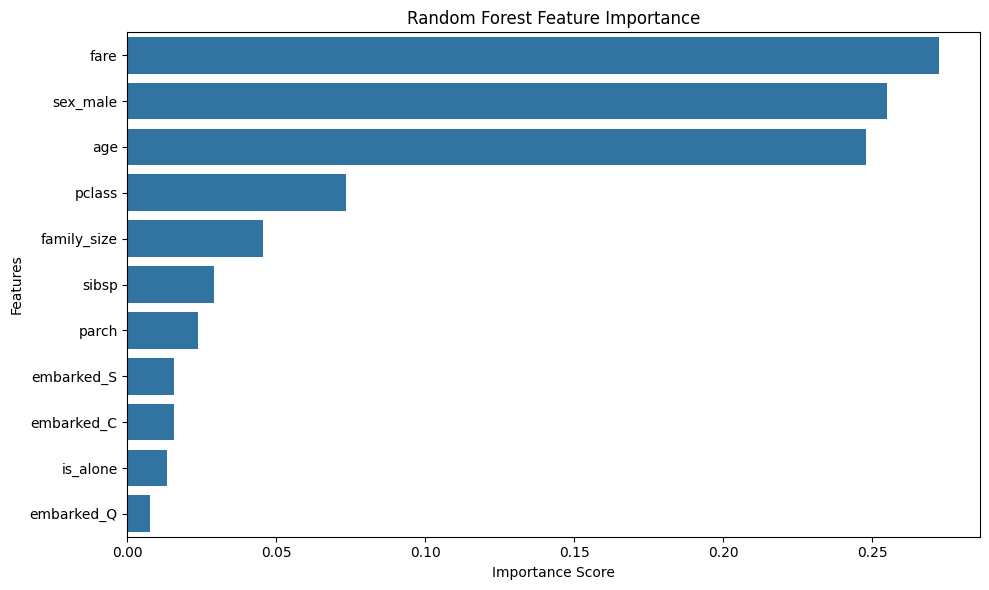

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Save and Reload the Best Performing Model

In this section, I saved the best-performing machine learning model using Joblib and tested its functionality after reloading it.

- Selected Random Forest as the best-performing model based on its evaluation metrics.
- Saved the trained model as a `.pkl` file using `joblib.dump()`.
- Reloaded the saved model using `joblib.load()`.
- Generated predictions using the reloaded model.
- Verified the model's performance by comparing its predictions with the actual test data.

This ensures that the trained model can be saved, reused, and applied to new data without training it again.

In [35]:
best_model = rf_model
best_model_name = "Random Forest"

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [36]:
import joblib

joblib.dump(best_model, 'best_titanic_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [37]:
loaded_model = joblib.load('best_titanic_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [38]:
loaded_predictions = loaded_model.predict(X_test)

print("Predictions:", loaded_predictions[:10])
print("Reloaded Model Accuracy:",
      round(accuracy_score(y_test, loaded_predictions) * 100, 2), "%")

Predictions: [0 0 0 1 0 1 1 0 1 1]
Reloaded Model Accuracy: 82.68 %


### Model Performance Analysis and Conclusion

The performance of Logistic Regression and Random Forest was evaluated using accuracy, precision, and recall.

Random Forest performed better than Logistic Regression across all three evaluation metrics. It achieved an accuracy of **82.68%**, precision of **80.28%**, and recall of **77.03%**, while Logistic Regression achieved an accuracy of 79.89%, precision of 77.14%, and recall of 72.97%.

Random Forest provided better overall prediction performance on the test dataset. Therefore, it was selected as the best-performing model and saved using Joblib for future use.